# Pandas Practice: Bike Share Trip Data

This notebook gives you practice using Pandas on a messier, more realistic dataset. You'll work with February 2014 trip data from a bike share scheme, cleaning column names, exploring patterns, filtering, grouping, and creating visualisations. A good data scientist doesn't always invent solutions from scratch; knowing where to look and how to adapt existing code is a core skill. If you get stuck, [Sebastian Raschka's Pandas tips](https://nbviewer.jupyter.org/github/rasbt/python_reference/blob/master/tutorials/things_in_pandas.ipynb) and the [Pandas documentation](https://pandas.pydata.org/docs/) are excellent references.

---

<center><img src="../assets/nextbike_bike_rental_berlin.jpg" width="800"/></center>

In [1]:
# --- Starter code: run this cell first ---
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("../data/bike_share_201402_trip_data.csv")
df.head()

,Trip ID,Duration,Start Date,Start Station,Start Terminal,End Date,End Station,End Terminal,Bike #,Subscription Type,Zip Code
0,4576,63,8/29/2013 14:13,South Van Ness at Market,66,8/29/2013 14:14,South Van Ness at Market,66,520,Subscriber,94127
1,4607,70,8/29/2013 14:42,San Jose City Hall,10,8/29/2013 14:43,San Jose City Hall,10,661,Subscriber,95138
2,4130,71,8/29/2013 10:16,Mountain View City Hall,27,8/29/2013 10:17,Mountain View City Hall,27,48,Subscriber,97214
3,4251,77,8/29/2013 11:29,San Jose City Hall,10,8/29/2013 11:30,San Jose City Hall,10,26,Subscriber,95060
4,4299,83,8/29/2013 12:02,South Van Ness at Market,66,8/29/2013 12:04,Market at 10th,67,319,Subscriber,94103


## Part 1: Cleaning and Exploring

### Challenge 1: How many trips are in the dataset?

Find the number of observations (rows) in the DataFrame.

In [2]:
print("Trips:", len(df))

Trips: 144015


### Challenge 2: Make the column names Pythonic

Rename all columns so they are:
- **Lowercase**
- Spaces replaced with `_`
- `#` replaced with `num`

Print the updated column names to verify.

In [3]:
# Chain vectorised string methods over all column names at once
df.columns = (df.columns.str.lower()
              .str.replace(" ", "_")
              .str.replace("#", "num"))
print(df.columns.tolist())

['trip_id', 'duration', 'start_date', 'start_station', 'start_terminal', 'end_date', 'end_station', 'end_terminal', 'bike_num', 'subscription_type', 'zip_code']


---

## Part 2: Subscription Analysis

### Challenge 3: Subscription types

How many types of subscription are there? What are they?

In [4]:
print("Number of types:", df["subscription_type"].nunique())
print("Types:", df["subscription_type"].unique().tolist())

Number of types: 2
Types: ['Subscriber', 'Customer']


### Challenge 4: Frequency of each subscription type

How many trips were made by each subscription type?

In [5]:
sub_counts = df["subscription_type"].value_counts()
sub_counts

subscription_type
Subscriber    113647
Customer       30368
Name: count, dtype: int64

### Challenge 5: Visualise subscription frequency, pie chart

Plot the frequency of each subscription type as a pie chart.

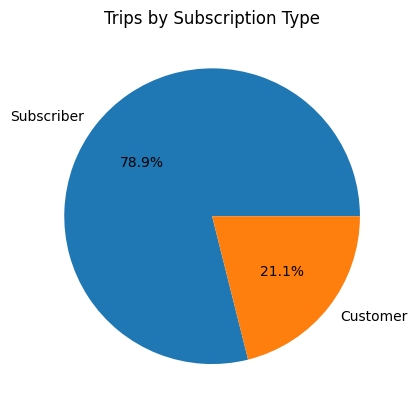

In [6]:
# autopct writes the percentage on each slice
sub_counts.plot(kind="pie", autopct="%1.1f%%", ylabel="",
                title="Trips by Subscription Type")
plt.show()

### Challenge 6: Visualise subscription frequency, bar chart

Plot the same data as a bar chart.

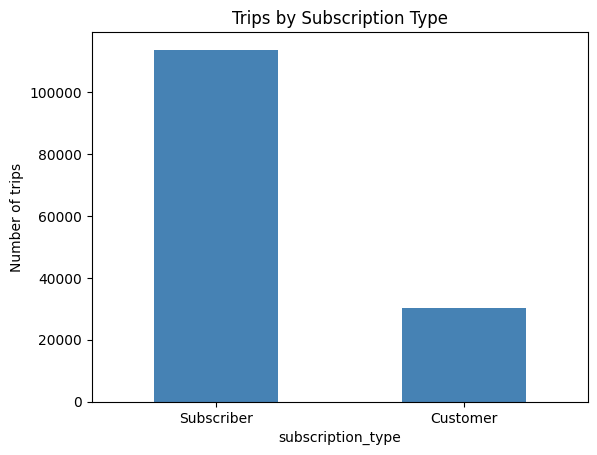

In [7]:
sub_counts.plot(kind="bar", rot=0, color="steelblue",
                title="Trips by Subscription Type")
plt.ylabel("Number of trips")
plt.show()

---

## Part 3: Station Analysis

### Challenge 7: Top 10 most popular start stations

Which 10 start stations appear most frequently in the data?

In [8]:
# value_counts is sorted high to low, so head(10) = the busiest
df["start_station"].value_counts().head(10)

start_station
San Francisco Caltrain (Townsend at 4th)         9838
Harry Bridges Plaza (Ferry Building)             7343
Embarcadero at Sansome                           6545
Market at Sansome                                5922
Temporary Transbay Terminal (Howard at Beale)    5113
Market at 4th                                    5030
2nd at Townsend                                  4987
San Francisco Caltrain 2 (330 Townsend)          4976
Steuart at Market                                4913
Townsend at 7th                                  4493
Name: count, dtype: int64

### Challenge 8: 10 least popular end stations

Which 10 end stations appear least often?

In [9]:
# ascending=True puts the rarest first
df["end_station"].value_counts(ascending=True).head(10)

end_station
Mezes Park                            5
San Jose Government Center           23
Broadway at Main                     56
Franklin at Maple                    93
San Antonio Shopping Center          93
San Mateo County Center             106
Redwood City Public Library         117
Castro Street and El Camino Real    129
Redwood City Medical Center         178
Broadway St at Battery St           205
Name: count, dtype: int64

### Challenge 9: Cross-tabulation of start stations by subscription type

Create a table that shows the count of trips for each `start_station` segmented by `subscription_type`, including row and column totals (subtotals).

> Hint: look up `pd.crosstab()` in the documentation.

In [10]:
# Rows = station, columns = subscription type, margins=True adds totals
station_table = pd.crosstab(df["start_station"],
                            df["subscription_type"], margins=True)
station_table.sort_values("All", ascending=False).head(15)

subscription_type,Customer,Subscriber,All
start_station,,,
All,30368,113647,144015
San Francisco Caltrain (Townsend at 4th),957,8881,9838
Harry Bridges Plaza (Ferry Building),2653,4690,7343
Embarcadero at Sansome,2938,3607,6545
Market at Sansome,972,4950,5922
Temporary Transbay Terminal (Howard at Beale),427,4686,5113
Market at 4th,1383,3647,5030
2nd at Townsend,882,4105,4987
San Francisco Caltrain 2 (330 Townsend),510,4466,4976


---

## Part 4: Trip Duration

### Challenge 10: Explore duration

What unit do you think the `duration` column uses? Find the shortest and longest trips. How many trips are as short as the minimum?

In [11]:
d = df["duration"]
print("Shortest:", d.min(), "| Longest:", d.max())
print("Median:", d.median())
print("Trips as short as the minimum:", (d == d.min()).sum())

# Check the unit: start and end time are given to the minute
start = pd.to_datetime(df["start_date"], format="%m/%d/%Y %H:%M")
end = pd.to_datetime(df["end_date"], format="%m/%d/%Y %H:%M")
clock_minutes = (end - start).dt.total_seconds() / 60
print("Median clock minutes:", clock_minutes.median())
print("Median duration / 60:", d.median() / 60)

Shortest: 60 | Longest: 722236
Median: 531.0
Trips as short as the minimum: 17


Median clock minutes: 9.0
Median duration / 60: 8.85


**My answer:** the unit is **seconds**. The median duration is 531, which is about 9 minutes, and the
median gap between start and end clock time is also about 9 minutes. The shortest trip is 60 s
(exactly one minute, 17 trips); the longest is 722,236 s, more than 8 days.
A minimum of exactly 60 s suggests that shorter rides were removed from the data (an assumption, not documented here).

### Challenge 11: Define and count "long" trips

Define what you consider a "long" trip (justify your threshold). How many trips meet that definition? What might explain the very long durations?

In [12]:
# My threshold: 1 hour. The median trip is 9 minutes, so 1 hour is
# more than 6x a normal ride: clearly not a quick hop across town.
long_threshold = 60 * 60
is_long = df["duration"] > long_threshold
print("Long trips (> 1 hour):", is_long.sum())
print("Share of all trips:", round(is_long.mean() * 100, 1), "%")
print("Longer than 1 day:", (df["duration"] > 24 * 3600).sum())

# Who takes the long trips?
df[is_long]["subscription_type"].value_counts()

Long trips (> 1 hour): 5695
Share of all trips: 4.0 %
Longer than 1 day: 82


subscription_type
Customer      5378
Subscriber     317
Name: count, dtype: int64

**My answer:** I call a trip "long" above 1 hour, because a normal trip takes about 9 minutes.
5,695 trips (4.0 %) are long, and 82 last more than a whole day.
Possible explanations (not proven by this data): bikes that were not docked properly so the clock kept
running, day-pass customers keeping a bike for sightseeing, or broken records. Most long trips come from
`Customer` (casual) riders, which fits the sightseeing idea.

### Challenge 12: Plot the duration distribution

Create a histogram of the `duration` column. Does it give clear insights? If not, filter to a more meaningful range and re-plot.

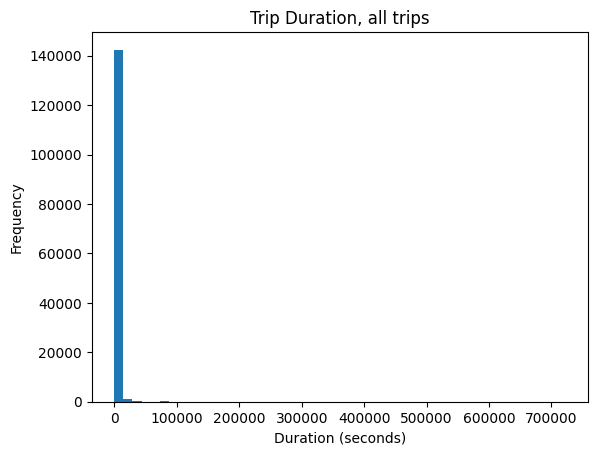

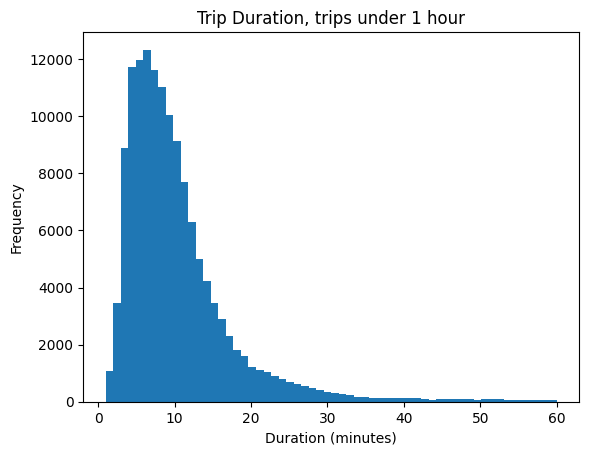

In [13]:
# All trips: a few huge values squash everything into one bar
df["duration"].plot(kind="hist", bins=50,
                    title="Trip Duration, all trips")
plt.xlabel("Duration (seconds)")
plt.show()

# Only trips under 1 hour, shown in minutes for easy reading
short_minutes = df.loc[df["duration"] < 3600, "duration"] / 60
short_minutes.plot(kind="hist", bins=60,
                   title="Trip Duration, trips under 1 hour")
plt.xlabel("Duration (minutes)")
plt.show()

**My answer:** the first histogram is useless: one bar holds almost every trip, because the 8-day
outliers stretch the axis. After keeping trips under 1 hour and switching to minutes, the shape appears:
most trips last 3 to 12 minutes, with a long tail to the right.

---

## Part 5: Data Cleaning (Advanced)

### Challenge 13: Normalise station names

The product team wants all station names to be lowercase with underscores as separators.

Example: `South Van Ness at Market` → `south_van_ness_at_market`

Apply this transformation to both the `start_station` and `end_station` columns.

> **Do NOT use a for loop.** Use a vectorised Pandas string method instead, it will be much faster.

In [14]:
# .str applies the string method to every row at once, no for loop
for col in ["start_station", "end_station"]:
    df[col] = df[col].str.lower().str.replace(" ", "_")

df[["start_station", "end_station"]].head()

,start_station,end_station
0,south_van_ness_at_market,south_van_ness_at_market
1,san_jose_city_hall,san_jose_city_hall
2,mountain_view_city_hall,mountain_view_city_hall
3,san_jose_city_hall,san_jose_city_hall
4,south_van_ness_at_market,market_at_10th


### Challenge 14: Open-ended exploration

Set a 15-minute timer. Use that time to explore the data guided by your own curiosity or hypotheses. What patterns can you find?

> Time-boxing is a useful technique when exploring new data: it prevents you from falling into rabbit holes and forces you to prioritise the most interesting questions.

Data covers: 2013-08-29 09:08:00 to 2014-02-28 23:20:00


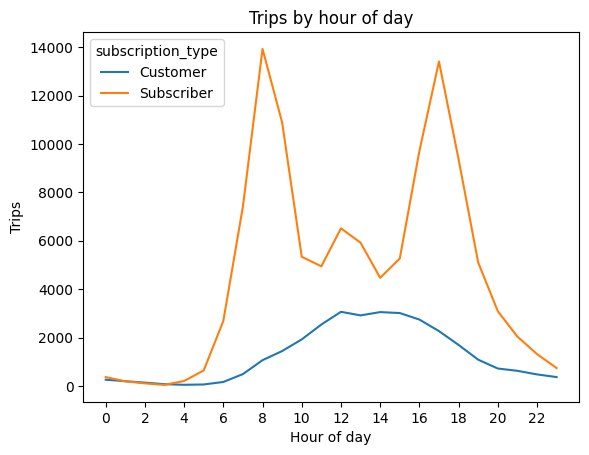

subscription_type  Customer  Subscriber
start_time                             
0                      3433       19705
1                      3217       21461
2                      3403       20248
3                      3871       21394
4                      4520       19763
5                      6340        6073
6                      5584        5003
subscription_type
Customer      17.8
Subscriber     7.8
Name: duration, dtype: float64


In [15]:
# My 15-minute exploration: WHEN do people ride, and does it differ
# between subscribers (commuters?) and customers (casual riders?)
df["start_time"] = pd.to_datetime(df["start_date"],
                                  format="%m/%d/%Y %H:%M")
print("Data covers:", df["start_time"].min(), "to", df["start_time"].max())

# 1) Trips per hour of the day, one line per subscription type
by_hour = pd.crosstab(df["start_time"].dt.hour, df["subscription_type"])
by_hour.plot(title="Trips by hour of day", xticks=range(0, 24, 2))
plt.xlabel("Hour of day")
plt.ylabel("Trips")
plt.show()

# 2) Weekdays vs weekend (Monday = 0, Sunday = 6)
by_day = pd.crosstab(df["start_time"].dt.dayofweek, df["subscription_type"])
print(by_day)

# 3) Typical trip length per type, in minutes
print((df.groupby("subscription_type")["duration"].median() / 60).round(1))

**What I found:**
- The file is named February 2014, but the trips run from 29 August 2013 to 28 February 2014 (six months).
- Subscribers ride in two rush-hour peaks (about 8 am and 5 pm) and mostly on weekdays: a commuter pattern.
- Customers ride more evenly through the day, relatively more at weekends, and their median trip
  (about 18 minutes) is more than twice as long as a subscriber's (about 8 minutes).
- Hypothesis for later: subscribers commute, customers explore. A product team could price and place bikes differently for the two groups.